# 02 · Ranking features (spec 9)

Spec 9 adds a second stage for reviewers with a history: retrieval returns ~100 candidates, a
LightGBM `lambdarank` model re-orders them and keeps the top 20. This notebook screens its
feature families before they are built: which ones separate the game the user reviews next from
the other candidates a retriever would return?

| # | Question |
|---|---|
| R1 | How much room is there between recall@20 and recall@100 (the ranker's ceiling)? |
| R2 | Which single features separate the true game from the other candidates (within-group AUC)? |
| R3 | How much does a ranker gain over retrieval order, with the spec's families and with all? |
| R4 | Which families matter: added alone to the retrieval score, and dropped from the full set? |
| R5 | Where does the ranker gain: users with a history longer than the tower's 20 games or not? |
| R6 | Negative reviews: avoidance or interest signal for ranking? |
| R7 | Playtime and language (need an ETL change): worth it for the ranker? |

**Setup, as in spec 9.** The time window after the retriever's cutoff `T1` (the champion's,
2026-05-01) is split at `T2` (70% of its rows). One query group per positive review (u, g, t) in
the window by a user with a positive review before t, at most 20 per user; candidates = the
retriever's top 100 for u's history strictly before t, games u already reviewed excluded, other
games u reviews positively later dropped. Label 1 for g. The ranker trains on groups before `T2`
(the last 20% by time for early stopping) and is tested after.

**Proxy retriever.** The champion's towers don't run on the public dataset, so a proxy produces
the candidates: SVD item embeddings of the positives before `T1`, the user as the mean of the
last 20 positives, plus `β` × standardized log positives of the game in the 13 weeks before the
month of t (without it, games released after `T1` can't be retrieved and recall@100 is ~7%). `β`
is tuned for recall@100. The proxy has no tags and its embeddings are not the item tower's:
absolute gains are optimistic, **read the ranking of the families**, and re-check on the
champion's candidates (spec 9). `game_price` is the price at scrape time, not as of t.

In [1]:
from datetime import datetime

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns
from IPython.display import Markdown, display

from steam_eda import cached, load_games, load_reviews, scan, settings
from steam_eda.ranking import (
    FAMILIES,
    FAMILY_NAMES,
    FEATURES,
    GameArrays,
    ProxyRetriever,
    Sequences,
    WeeklyPopularity,
    build_groups,
    group_auc,
    group_features,
    group_sizes,
    hits,
    ranking_metrics,
    subsample,
    svd_embeddings,
    weekly_counts,
    with_gi,
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 4)
pl.Config.set_tbl_rows(40)

S = settings()
SEED = S.seed
T1 = datetime(2026, 5, 1)  # the champion's cutoff (local-9cc8927-a3-len20-attn)
TRAIN_FRACTION = 0.7  # RANKER_TRAIN_FRACTION: share of the window's rows before T2
HISTORY = 20  # the tower's history length
K = 100  # RETRIEVAL_CANDIDATES
TOP = 20  # what the ranker keeps
CAP = 20  # RANKER_MAX_GROUPS_PER_USER
MAX_TRAIN_GROUPS, MAX_TEST_GROUPS = 60_000, 30_000
SVD_FRACTION = max(S.sample_users, 0.15)  # users behind the proxy's item embeddings
BETAS = [0.0, 0.1, 0.2, 0.3, 0.5, 0.8]
SPEC = list("RCAHNFU")  # families in spec 9 (L and P need an ETL change)
print(f"data: {S.data_dir}  sample: {S.sample_users:.1%} of users  SVD users: {SVD_FRACTION:.0%}")

findings: list[dict] = []


def note(question: str, evidence: str, verdict: str) -> None:
    findings.append({"question": question, "evidence": evidence, "verdict": verdict})
    display(Markdown(f"**{question}** · {evidence}\n\n→ {verdict}"))

/home/sadelcarpio/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/claude-1000/matplotlib-j3blhde_ because there was an issue with the default path (/home/sadelcarpio/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


data: /home/sadelcarpio/code/steam-recsys-e2e/notebooks/data  sample: 5.0% of users  SVD users: 15%


## Data

Game arrays (tags, genres, developers, price, release date), weekly positives per game over every
review (popularity as of t uses the weeks before t's week), each game's share of reviews per
language before `T1`, and the user sample.

In [2]:
games_df = load_games()
games = GameArrays.build(games_df)
weekly = cached("ranking_weekly_counts", lambda: weekly_counts(scan("reviews")))
pop = WeeklyPopularity.build(weekly, games.gid2gi)
lang = cached(
    f"ranking_language_before_{T1:%Y%m%d}",
    lambda: (
        scan("reviews")
        .filter(pl.col("reviewed_at") < T1)
        .group_by("game_id", "language")
        .agg(n=pl.len())
        .collect(engine="streaming")
    ),
)
lang = with_gi(lang, games.gid2gi).with_columns(share=pl.col("n") / pl.col("n").sum().over("gi"))
LANGUAGE_SHARE = {
    (g, la): s for g, la, s in zip(lang["gi"], lang["language"], lang["share"], strict=True)
}

COLUMNS = ["user_id", "game_id", "is_positive", "reviewed_at", "language", "playtime_at_review"]
seq = Sequences.build(load_reviews(columns=COLUMNS), games.gid2gi)
window = np.sort(seq.ts[seq.ts >= T1.timestamp()])
T2 = datetime.fromtimestamp(int(window[int(TRAIN_FRACTION * (len(window) - 1))]))
SNAPSHOT = datetime.fromtimestamp(int(seq.ts.max()))
train_all, test_all = build_groups(seq, T1, T2, cap=CAP, seed=SEED)
train_g = subsample(train_all, MAX_TRAIN_GROUPS, SEED)
test_g = subsample(test_all, MAX_TEST_GROUPS, SEED)
print(
    f"{len(seq.ts):,} reviews by {len(seq.bounds) - 1:,} users; T1 {T1:%Y-%m-%d}, "
    f"T2 {T2:%Y-%m-%d}, snapshot {SNAPSHOT:%Y-%m-%d}\n"
    f"groups: train {len(train_all):,} (kept {len(train_g):,}), "
    f"test {len(test_all):,} (kept {len(test_g):,})"
)

6,033,992 reviews by 1,943,056 users; T1 2026-05-01, T2 2026-09-06, snapshot 2026-10-29
groups: train 231,838 (kept 60,000), test 97,917 (kept 30,000)


## Proxy retriever

Item embeddings from positives before `T1` (a larger user sample), then `β` tuned on 5,000
training groups for recall@100.

In [3]:
svd_rows = with_gi(
    load_reviews(
        fraction=SVD_FRACTION,
        columns=["user_id", "game_id"],
        filter=(pl.col("reviewed_at") < T1) & pl.col("is_positive"),
        seed=SEED + 7,
    ),
    games.gid2gi,
)
emb, counts_before = svd_embeddings(svd_rows, games.n, dim=64, seed=SEED)
del svd_rows
top_counts = np.sort(counts_before)[::-1]
min_pool = min(30 * SVD_FRACTION, top_counts[min(len(top_counts), 500) - 1])
months, m = [], datetime(T1.year, T1.month, 1)
while m <= SNAPSHOT:
    months.append(m)
    m = datetime(m.year + m.month // 12, m.month % 12 + 1, 1)
retriever = ProxyRetriever.build(emb, counts_before, pop, months, HISTORY, min_pool)

tune = train_g.take(np.arange(min(5_000, len(train_g))))
rows = []
for beta in BETAS:
    retriever.beta = beta
    c, _ = retriever.retrieve(seq, tune, K)
    h = hits(seq, tune, c)
    rows.append({"beta": beta, **{f"recall@{k}": h[:, :k].any(1).mean() for k in (10, 20, K)}})
beta_table = pl.DataFrame(rows)
retriever.beta = float(beta_table.sort(f"recall@{K}", descending=True)["beta"][0])
print(f"pool: {len(retriever.pool):,} games; beta = {retriever.beta}")
beta_table

pool: 48,134 games; beta = 0.5


beta,recall@10,recall@20,recall@100
f64,f64,f64,f64
0.0,0.0174,0.03,0.0764
0.1,0.051,0.0734,0.2158
0.2,0.0556,0.0894,0.246
0.3,0.058,0.0992,0.2614
0.5,0.061,0.1022,0.2698
0.8,0.0644,0.109,0.2672


In [4]:
c_tr, s_tr = retriever.retrieve(seq, train_g, K)
c_te, s_te = retriever.retrieve(seq, test_g, K)
h_te = hits(seq, test_g, c_te)
recall_te = {k: float(h_te[:, :k].any(1).mean()) for k in (10, TOP, 30, K)}
display(pl.DataFrame({"k": list(recall_te), "test recall": list(recall_te.values())}))
note(
    "R1 room for a ranker",
    f"proxy retriever on the test window: recall@{TOP} {recall_te[TOP]:.3f}, recall@{K} "
    f"{recall_te[K]:.3f} (the champion, warm rows after T1: ~0.17 @30, ~0.30 @100)",
    f"The right game is in the top {K} {recall_te[K] / max(recall_te[TOP], 1e-9):.1f}× as often "
    f"as in the top {TOP}: re-ordering {K} candidates has room, bounded by recall@{K}.",
)

k,test recall
i64,f64
10,0.052
20,0.0853
30,0.109267
100,0.211533


**R1 room for a ranker** · proxy retriever on the test window: recall@20 0.085, recall@100 0.212 (the champion, warm rows after T1: ~0.17 @30, ~0.30 @100)

→ The right game is in the top 100 2.5× as often as in the top 20: re-ordering 100 candidates has room, bounded by recall@100.

## Features

Spec 9's families plus two that need an ETL change (`language`, `playtime_at_review` are in the
public dataset but dropped by `stg_steam__reviews`):

| Family | Features |
|---|---|
| R retrieval | score, rank |
| C candidate | log positives as of t (lifetime, 30 d, 90 d), positive ratio, is_free, log price, age at t |
| A affinity | tag cosine (full history, last 20), developer / publisher share of u's positives, genre / category overlap |
| H history | max / mean embedding similarity to u's positives: full, last 20, older than the last 20 |
| N negatives | max embedding similarity, tag cosine and developer share of u's negatively reviewed games |
| F fit | popularity, release date and price of c relative to u's positives; u's free share |
| U user | positive / negative counts, positive rate, days since last review, history > 20 |
| L language | share of c's reviews (before T1) in u's dominant review language |
| P playtime | tag cosine and embedding similarity with a profile weighted by log hours at review |

In [5]:
X_tr, y_tr, q_tr = group_features(
    seq, train_g, c_tr, s_tr, games, pop, emb, LANGUAGE_SHARE, HISTORY, keep_missing=False
)
X_te, y_te, q_te = group_features(
    seq, test_g, c_te, s_te, games, pop, emb, LANGUAGE_SHARE, HISTORY, keep_missing=True
)
print(
    f"train: {len(group_sizes(q_tr)):,} groups with the positive, {len(y_tr):,} rows; "
    f"test: {len(group_sizes(q_te)):,} groups, {len(y_te):,} rows"
)

train: 14,828 groups with the positive, 1,477,107 rows; test: 30,000 groups, 2,996,445 rows


## R2 · Single features

Within-group AUC: for each test group with the true game among its candidates, the probability
that the true game has a higher value than another candidate (ties ½), averaged over groups. 0.5
= no signal; below 0.5 = higher values make a game *less* likely. User features are constant in
a group (0.5 by construction): they can only help through splits with candidate features.

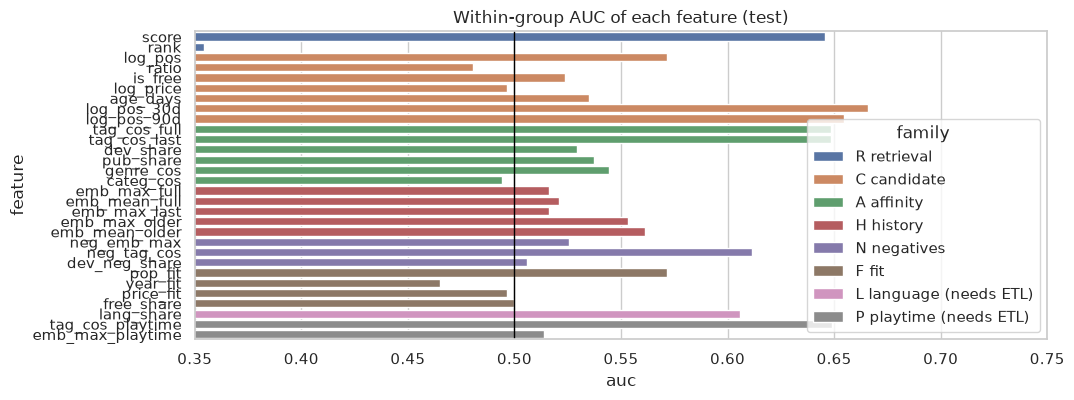

family,feature,auc,groups
str,str,f64,i64
"""C candidate""","""log_pos_30d""",0.665929,6346
"""C candidate""","""log_pos_90d""",0.654403,6346
"""P playtime (needs ETL)""","""tag_cos_playtime""",0.649008,6346
"""A affinity""","""tag_cos_last""",0.648498,6346
"""A affinity""","""tag_cos_full""",0.64834,6346
"""R retrieval""","""score""",0.64563,6346
"""N negatives""","""neg_tag_cos""",0.611662,1737
"""L language (needs ETL)""","""lang_share""",0.605883,6346
"""C candidate""","""log_pos""",0.571687,6346


In [6]:
auc_rows = []
for fam, feats in FAMILIES.items():
    for f in feats:
        a, n = group_auc(X_te[:, FEATURES.index(f)], y_te, q_te)
        auc_rows.append(
            {"family": f"{fam} {FAMILY_NAMES[fam]}", "feature": f, "auc": a, "groups": n}
        )
aucs = pl.DataFrame(auc_rows)
plot = aucs.filter(~pl.col("family").str.starts_with("U")).with_columns(
    signal=(pl.col("auc") - 0.5).abs()
)
ax = sns.barplot(plot.to_pandas(), x="auc", y="feature", hue="family", dodge=False)
ax.axvline(0.5, color="black", lw=1)
ax.set(title="Within-group AUC of each feature (test)", xlim=(0.35, 0.75))
plt.show()
aucs.sort("auc", descending=True)

## R3 · Ranker vs retrieval order

LightGBM `lambdarank` (binary labels), early stopping on NDCG@20 of the last 20% of the training
groups by time.

In [7]:
cut = int(np.sum(group_sizes(q_tr)[: int(0.8 * len(group_sizes(q_tr)))]))
PARAMS = dict(
    objective="lambdarank", metric="ndcg", eval_at=[TOP], learning_rate=0.05, num_leaves=31,
    min_data_in_leaf=100, feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
    lambdarank_truncation_level=30, verbose=-1, seed=SEED,
)  # fmt: skip


def fit(feats: list[str]):
    idx = [FEATURES.index(f) for f in feats]
    train = lgb.Dataset(X_tr[:cut, idx], y_tr[:cut], group=group_sizes(q_tr[:cut]))
    valid = lgb.Dataset(X_tr[cut:, idx], y_tr[cut:], group=group_sizes(q_tr[cut:]), reference=train)
    params = PARAMS | {"min_data_in_leaf": min(100, max(1, cut // 50))}
    model = lgb.train(
        params, train, 500, valid_sets=[valid], callbacks=[lgb.early_stopping(30, verbose=False)]
    )
    return model, ranking_metrics(model.predict(X_te[:, idx]), y_te, q_te, (10, TOP))


def fams(letters) -> list[str]:
    return [f for x in letters for f in FAMILIES[x]]


retrieval = ranking_metrics(-X_te[:, FEATURES.index("rank")], y_te, q_te, (10, TOP))
spec_model, spec_m = fit(fams(SPEC))
full_model, full_m = fit(FEATURES)
r3 = pl.DataFrame(
    [
        {"order": "retrieval", **retrieval},
        {"order": "ranker, spec 9 families (RCAHNFU)", **spec_m},
        {"order": "ranker, + language + playtime", **full_m},
    ]
)
display(r3)
gain = spec_m[f"recall@{TOP}"] - retrieval[f"recall@{TOP}"]
note(
    "R3 ranker vs retrieval order",
    f"recall@{TOP} {retrieval[f'recall@{TOP}']:.3f} → {spec_m[f'recall@{TOP}']:.3f} (spec "
    f"families) → {full_m[f'recall@{TOP}']:.3f} (+ language, playtime); NDCG@{TOP} "
    f"{retrieval[f'ndcg@{TOP}']:.3f} → {spec_m[f'ndcg@{TOP}']:.3f}",
    f"A ranker over {K} candidates gains {gain:+.3f} recall@{TOP} on the proxy (optimistic: the "
    "proxy has no tags). Worth building; gate it on the champion's candidates."
    if gain > 0.005
    else "No clear gain over retrieval order on the proxy.",
)

order,recall@10,recall@20,ndcg@20
str,f64,f64,f64
"""retrieval""",0.052067,0.0855,0.037395
"""ranker, spec 9 families (RCAHN…",0.0811,0.1182,0.055498
"""ranker, + language + playtime""",0.0867,0.122733,0.058326


**R3 ranker vs retrieval order** · recall@20 0.086 → 0.118 (spec families) → 0.123 (+ language, playtime); NDCG@20 0.037 → 0.055

→ A ranker over 100 candidates gains +0.033 recall@20 on the proxy (optimistic: the proxy has no tags). Worth building; gate it on the champion's candidates.

## R4 · Families: added alone, dropped from all

Left: the retrieval family plus one other (what each family brings on its own). Right: every
family but one (what is lost without it, given the others). A family that helps alone but not
when dropped is redundant with the others.

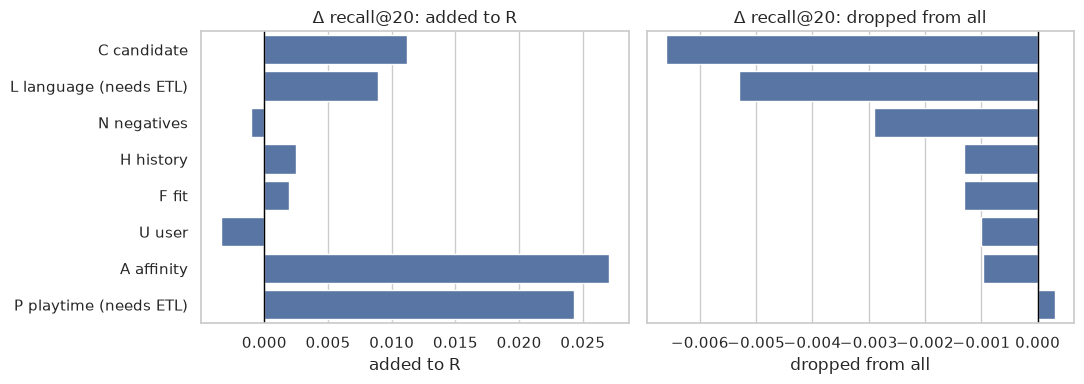

family,added to R,dropped from all
str,f64,f64
"""C candidate""",0.011167,-0.0066
"""L language (needs ETL)""",0.008933,-0.0053
"""N negatives""",-0.001033,-0.0029
"""H history""",0.0025,-0.0013
"""F fit""",0.0019,-0.0013
"""U user""",-0.003433,-0.001
"""A affinity""",0.027067,-0.000967
"""P playtime (needs ETL)""",0.0243,0.0003


In [8]:
_, r_only = fit(FAMILIES["R"])
rows = []
for fam in FAMILIES:
    if fam == "R":
        continue
    _, add = fit(FAMILIES["R"] + FAMILIES[fam])
    _, drop = fit([f for f in FEATURES if f not in FAMILIES[fam]])
    rows.append(
        {
            "family": f"{fam} {FAMILY_NAMES[fam]}",
            "added to R": add[f"recall@{TOP}"] - r_only[f"recall@{TOP}"],
            "dropped from all": drop[f"recall@{TOP}"] - full_m[f"recall@{TOP}"],
        }
    )
r4 = pl.DataFrame(rows).sort("dropped from all")
fig, axes = plt.subplots(1, 2, sharey=True)
for ax, col in zip(axes, ["added to R", "dropped from all"], strict=True):
    sns.barplot(r4.to_pandas(), x=col, y="family", ax=ax, color="C0")
    ax.axvline(0, color="black", lw=1)
    ax.set(title=f"Δ recall@{TOP}: {col}", ylabel="")
plt.tight_layout()
plt.show()
r4

**R4 feature families** · Δ recall@20 when dropped: C candidate -0.0066, L language (needs ETL) -0.0053, N negatives -0.0029, H history -0.0013, F fit -0.0013, U user -0.0010, A affinity -0.0010, P playtime (needs ETL) +0.0003

→ Most valuable given the others: C candidate. Families with |Δ| < 0.001 when dropped are redundant on this proxy (keep only if cheap).

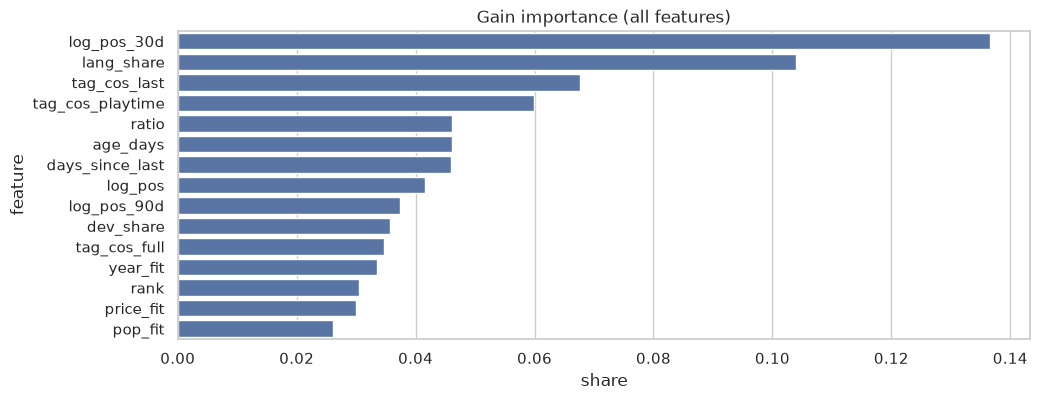

**R4b recent popularity as of t** · within-group AUC: log_pos 0.572, log_pos_30d 0.666, log_pos_90d 0.654; top feature by gain: log_pos_30d

→ Recent popularity (last 30 / 90 days as of t) separates the target better than lifetime popularity; the towers can't learn it (logQ removes popularity): a ranker feature.

In [9]:
best = r4.row(0, named=True)
note(
    "R4 feature families",
    f"Δ recall@{TOP} when dropped: "
    + ", ".join(f"{r['family']} {r['dropped from all']:+.4f}" for r in r4.iter_rows(named=True)),
    f"Most valuable given the others: {best['family']}. Families with |Δ| < 0.001 when dropped "
    "are redundant on this proxy (keep only if cheap).",
)
imp = pl.DataFrame(
    {"feature": FEATURES, "gain": full_model.feature_importance("gain")}
).with_columns(share=pl.col("gain") / pl.col("gain").sum())
top_feats = imp.sort("gain", descending=True).head(15)
ax = sns.barplot(top_feats.to_pandas(), x="share", y="feature", color="C0")
ax.set(title="Gain importance (all features)")
plt.show()
top_pop = aucs.filter(pl.col("feature").is_in(["log_pos", "log_pos_30d", "log_pos_90d"]))
note(
    "R4b recent popularity as of t",
    "within-group AUC: "
    + ", ".join(f"{r['feature']} {r['auc']:.3f}" for r in top_pop.iter_rows(named=True))
    + f"; top feature by gain: {top_feats['feature'][0]}",
    "Recent popularity (last 30 / 90 days as of t) separates the target better than lifetime "
    "popularity; the towers can't learn it (logQ removes popularity): a ranker feature."
    if top_pop.filter(pl.col("feature") == "log_pos_30d")["auc"][0]
    > top_pop.filter(pl.col("feature") == "log_pos")["auc"][0]
    else "Lifetime popularity is as good as the recent windows.",
)

## R5 · Long histories

The tower reads the last 20 positives; the ranker also sees the rest. Split of the test groups by
history length.

In [10]:
pred = full_model.predict(X_te)
long_rows = X_te[:, FEATURES.index("hist_gt_last")] == 1
rows = []
for name, mask in [(f"≤ {HISTORY} positives", ~long_rows), (f"> {HISTORY} positives", long_rows)]:
    groups_n = len(group_sizes(q_te[mask]))
    base = ranking_metrics(-X_te[mask, FEATURES.index("rank")], y_te[mask], q_te[mask], (TOP,))
    ranked = ranking_metrics(pred[mask], y_te[mask], q_te[mask], (TOP,))
    rows.append(
        {"history": name, "groups": groups_n, "retrieval": base[f"recall@{TOP}"],
         "ranker": ranked[f"recall@{TOP}"]}
    )  # fmt: skip
r5 = pl.DataFrame(rows)
display(r5)
older = aucs.filter(pl.col("feature") == "emb_max_older").row(0, named=True)
note(
    "R5 long histories",
    f"{r5['groups'][1] / max(r5['groups'].sum(), 1):.0%} of test groups have > {HISTORY} "
    f"positives; recall@{TOP} there {r5['retrieval'][1]:.3f} → {r5['ranker'][1]:.3f} (≤ "
    f"{HISTORY}: {r5['retrieval'][0]:.3f} → {r5['ranker'][0]:.3f}); similarity to the older "
    f"history AUC {older['auc']:.3f} on {older['groups']:,} groups",
    "Retrieval is weakest for long histories and the ranker gains most there; the older-history "
    "features carry signal but cover few groups: cheap, keep them.",
)

history,groups,retrieval,ranker
str,i64,f64,f64
"""≤ 20 positives""",24896,0.097526,0.13709
"""> 20 positives""",5104,0.026842,0.052704


**R5 long histories** · 17% of test groups have > 20 positives; recall@20 there 0.027 → 0.053 (≤ 20: 0.098 → 0.137); similarity to the older history AUC 0.553 on 490 groups

→ Retrieval is weakest for long histories and the ranker gains most there; the older-history features carry signal but cover few groups: cheap, keep them.

## R6 · Negative reviews

Spec 17 Q7 found negatively reviewed games sit in the user's own taste region. For ranking: does
similarity to u's negatives push a candidate down (avoidance) or up (interest)?

In [11]:
neg = aucs.filter(pl.col("family").str.starts_with("N"))
display(neg)
tag = neg.filter(pl.col("feature") == "neg_tag_cos").row(0, named=True)
note(
    "R6 negatives in ranking",
    ", ".join(f"{r['feature']} AUC {r['auc']:.3f}" for r in neg.iter_rows(named=True))
    + f" ({tag['groups']:,} groups with a negative review)",
    "Similarity to disliked games makes a candidate *more* likely (interest, as in Q7): keep the "
    "tag cosine as a feature and let the ranker learn its sign; it is not an avoidance filter."
    if tag["auc"] > 0.52
    else "Similarity to disliked games pushes candidates down: an avoidance signal."
    if tag["auc"] < 0.48
    else "No signal either way.",
)

family,feature,auc,groups
str,str,f64,i64
"""N negatives""","""neg_emb_max""",0.525818,1737
"""N negatives""","""neg_tag_cos""",0.611662,1737
"""N negatives""","""dev_neg_share""",0.505755,1737


**R6 negatives in ranking** · neg_emb_max AUC 0.526, neg_tag_cos AUC 0.612, dev_neg_share AUC 0.506 (1,737 groups with a negative review)

→ Similarity to disliked games makes a candidate *more* likely (interest, as in Q7): keep the tag cosine as a feature and let the ranker learn its sign; it is not an avoidance filter.

## R7 · Language and playtime (need an ETL change)

Both columns are in the raw reviews but not in `interactions`. Worth a mart change for ranking?

In [12]:
r7 = aucs.filter(
    pl.col("family").str.slice(0, 1).is_in(["L", "P"]) | pl.col("feature").is_in(["tag_cos_full"])
)
display(r7)
drop = {r["family"][0]: r["dropped from all"] for r in r4.iter_rows(named=True)}
la = aucs.filter(pl.col("feature") == "lang_share")["auc"][0]
tp, tf = (
    aucs.filter(pl.col("feature") == f)["auc"][0] for f in ["tag_cos_playtime", "tag_cos_full"]
)
note(
    "R7 language and playtime",
    f"lang_share AUC {la:.3f}, Δ recall@{TOP} when dropped {drop['L']:+.4f}; playtime-weighted "
    f"tag cosine AUC {tp:.3f} vs count-weighted {tf:.3f}, dropped {drop['P']:+.4f}",
    ("Language is worth the mart change (u's dominant language vs c's audience). "
     if drop["L"] < -0.002 else "Language adds little. ")
    + ("Playtime adds little as a profile weight: only graded labels remain to test."
       if abs(tp - tf) < 0.005 and drop["P"] > -0.002 else "Playtime-weighted profiles help."),
)  # fmt: skip

family,feature,auc,groups
str,str,f64,i64
"""A affinity""","""tag_cos_full""",0.64834,6346
"""L language (needs ETL)""","""lang_share""",0.605883,6346
"""P playtime (needs ETL)""","""tag_cos_playtime""",0.649008,6346
"""P playtime (needs ETL)""","""emb_max_playtime""",0.51376,6346


**R7 language and playtime** · lang_share AUC 0.606, Δ recall@20 when dropped -0.0053; playtime-weighted tag cosine AUC 0.649 vs count-weighted 0.648, dropped +0.0003

→ Language is worth the mart change (u's dominant language vs c's audience). Playtime adds little as a profile weight: only graded labels remain to test.

## Findings

Screening on a proxy retriever: re-check on the champion's candidates (spec 9 asks for the
drop-one-family deltas in `ranker.json`).

In [13]:
display(
    Markdown(
        "\n".join(
            ["| Question | Evidence | Verdict |", "|---|---|---|"]
            + [f"| {f['question']} | {f['evidence']} | {f['verdict']} |" for f in findings]
        )
    )
)

| Question | Evidence | Verdict |
|---|---|---|
| R1 room for a ranker | proxy retriever on the test window: recall@20 0.085, recall@100 0.212 (the champion, warm rows after T1: ~0.17 @30, ~0.30 @100) | The right game is in the top 100 2.5× as often as in the top 20: re-ordering 100 candidates has room, bounded by recall@100. |
| R3 ranker vs retrieval order | recall@20 0.086 → 0.118 (spec families) → 0.123 (+ language, playtime); NDCG@20 0.037 → 0.055 | A ranker over 100 candidates gains +0.033 recall@20 on the proxy (optimistic: the proxy has no tags). Worth building; gate it on the champion's candidates. |
| R4 feature families | Δ recall@20 when dropped: C candidate -0.0066, L language (needs ETL) -0.0053, N negatives -0.0029, H history -0.0013, F fit -0.0013, U user -0.0010, A affinity -0.0010, P playtime (needs ETL) +0.0003 | Most valuable given the others: C candidate. Families with |Δ| < 0.001 when dropped are redundant on this proxy (keep only if cheap). |
| R4b recent popularity as of t | within-group AUC: log_pos 0.572, log_pos_30d 0.666, log_pos_90d 0.654; top feature by gain: log_pos_30d | Recent popularity (last 30 / 90 days as of t) separates the target better than lifetime popularity; the towers can't learn it (logQ removes popularity): a ranker feature. |
| R5 long histories | 17% of test groups have > 20 positives; recall@20 there 0.027 → 0.053 (≤ 20: 0.098 → 0.137); similarity to the older history AUC 0.553 on 490 groups | Retrieval is weakest for long histories and the ranker gains most there; the older-history features carry signal but cover few groups: cheap, keep them. |
| R6 negatives in ranking | neg_emb_max AUC 0.526, neg_tag_cos AUC 0.612, dev_neg_share AUC 0.506 (1,737 groups with a negative review) | Similarity to disliked games makes a candidate *more* likely (interest, as in Q7): keep the tag cosine as a feature and let the ranker learn its sign; it is not an avoidance filter. |
| R7 language and playtime | lang_share AUC 0.606, Δ recall@20 when dropped -0.0053; playtime-weighted tag cosine AUC 0.649 vs count-weighted 0.648, dropped +0.0003 | Language is worth the mart change (u's dominant language vs c's audience). Playtime adds little as a profile weight: only graded labels remain to test. |